# 04 - Test Evaluation, Error Analysis & App Artefacts

1. Compare the CLIP baseline with the fine-tuned model on the untouched **test** split.
2. Break results down by type of modification.
3. Look at the failures.
4. Calibrate similarity thresholds for High / Medium / Low risk.
5. Export the search gallery used by the Streamlit app.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

DATA_DIR = ROOT / "data" / "dummy_logos"
IMAGE_DIR = DATA_DIR / "images"
ASSETS = ROOT / "assets"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
for d in (ASSETS, RESULTS, MODELS):
    d.mkdir(exist_ok=True)
SEED = 42

import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss
from PIL import Image
from model import load_head, apply_head, get_device
from metrics import retrieval_eval, summarize, top_k, pair_scores, choose_thresholds
from viz import show_retrieval

device = get_device()
df = pd.read_csv(DATA_DIR / "metadata.csv")
emb = np.load(ROOT / "data" / "embeddings_clip.npy")
head = load_head(MODELS / "projection_head.pt", device)

test_mask = (df.split == "test").values
test_df = df[test_mask].reset_index(drop=True)
labels = test_df.parent_id.values
paths = test_df.filename.map(lambda f: IMAGE_DIR / f).values

emb_base = emb[test_mask]
emb_ft = apply_head(head, emb_base, device)
print("test images:", len(test_df), " distinct marks:", test_df.parent_id.nunique())

test images: 1350  distinct marks: 150


## 1. Baseline vs fine-tuned (test split)

In [2]:
pq_base = retrieval_eval(emb_base, labels)
pq_ft = retrieval_eval(emb_ft, labels)
results = pd.DataFrame({"CLIP baseline": summarize(pq_base),
                        "CLIP + fine-tuned head": summarize(pq_ft)})
results["improvement (pts)"] = (results.iloc[:, 1] - results.iloc[:, 0]) * 100

with open(RESULTS / "test_metrics.json", "w") as f:
    json.dump(results.to_dict(), f, indent=2)
results.style.format({"CLIP baseline": "{:.3f}", "CLIP + fine-tuned head": "{:.3f}",
                      "improvement (pts)": "{:+.1f}"})

,CLIP baseline,CLIP + fine-tuned head,improvement (pts)
recall@1,0.917,0.996,+7.9
recall@5,0.949,0.999,+5.0
recall@10,0.957,1.000,+4.3
mAP,0.690,0.967,+27.8


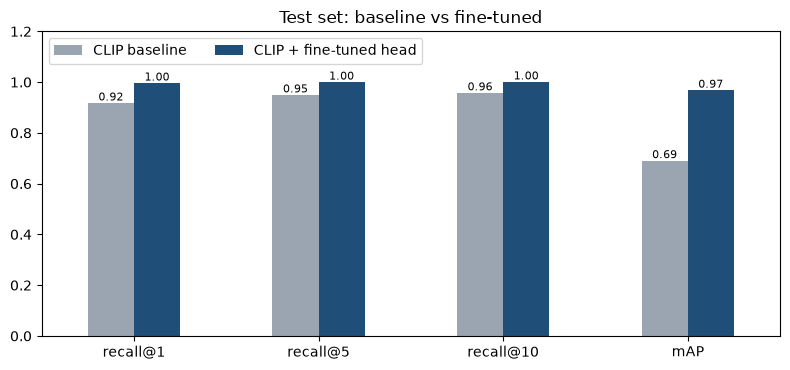

| Metric | CLIP baseline | + Fine-tuned head |
|---|---|---|
| recall@1 | 0.917 | **0.996** |
| recall@5 | 0.949 | **0.999** |
| recall@10 | 0.957 | **1.000** |
| mAP | 0.690 | **0.967** |


In [9]:
ax = results.iloc[:, :2].plot.bar(figsize=(8, 3.8), color=["#9aa5b1", "#1f4e79"], rot=0)
ax.set_ylim(0, 1.2)
ax.legend(loc="upper left", ncol=2)
ax.set_title("Test set: baseline vs fine-tuned")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "metrics_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

# Markdown table ready to paste into README.md
md = ["| Metric | CLIP baseline | + Fine-tuned head |", "|---|---|---|"]
for metric, row in results.iterrows():
    md.append(f"| {metric} | {row.iloc[0]:.3f} | **{row.iloc[1]:.3f}** |")
(RESULTS / "metrics_table.md").write_text("\n".join(md))
print("\n".join(md))

## 2. Which modifications are hardest?
Recall@1 for queries containing each modification (a variant can contain several).

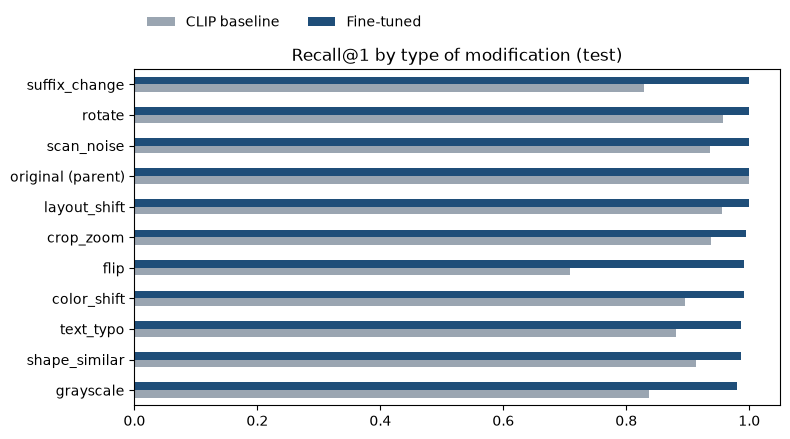

,CLIP baseline,Fine-tuned
t,,
grayscale,0.837,0.980
shape_similar,0.913,0.986
text_typo,0.881,0.987
color_shift,0.896,0.991
flip,0.708,0.992
crop_zoom,0.938,0.995
layout_shift,0.956,1.000
original (parent),1.000,1.000
scan_noise,0.936,1.000


In [4]:
q = test_df[["variant_types"]].copy()
q["variant_types"] = q["variant_types"].fillna("").replace("", "original (parent)")
q["base_r1"] = pq_base["recall@1"]
q["ft_r1"] = pq_ft["recall@1"]
by_type = (q.assign(t=q.variant_types.str.split("+")).explode("t")
             .groupby("t")[["base_r1", "ft_r1"]].mean()
             .sort_values("ft_r1"))
by_type.columns = ["CLIP baseline", "Fine-tuned"]

ax = by_type.plot.barh(figsize=(8, 4.5), color=["#9aa5b1", "#1f4e79"])
ax.set_xlim(0, 1.05)
ax.set_ylabel("")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, frameon=False)
ax.set_title("Recall@1 by type of modification (test)")
plt.tight_layout()
plt.savefig(ASSETS / "recall_by_modification.png", dpi=110, bbox_inches="tight")
plt.show()
by_type.style.format("{:.3f}")

## 3. Error analysis
Queries where the fine-tuned model's **top-1 result is a different mark**.

6 of 1350 queries fail at rank 1 (0.4%)


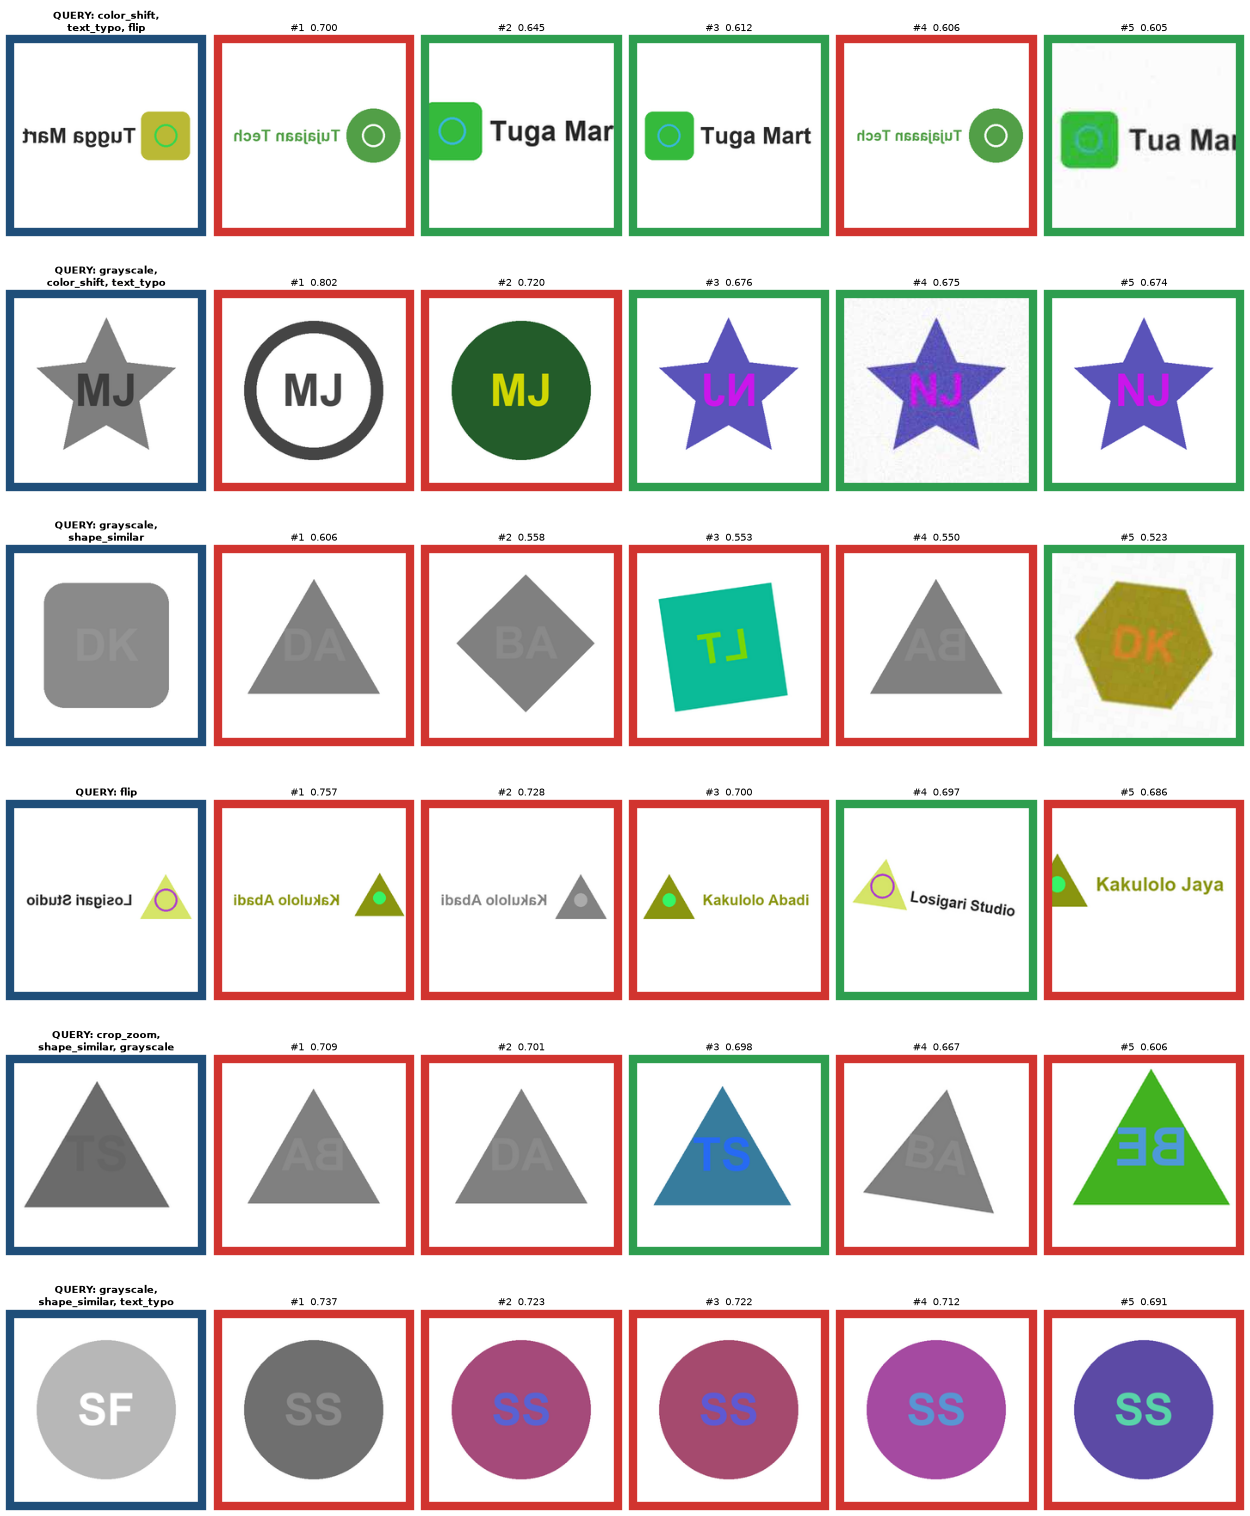

In [5]:
fail_idx = np.where(~pq_ft["recall@1"])[0]
print(f"{len(fail_idx)} of {len(test_df)} queries fail at rank 1 "
      f"({len(fail_idx) / len(test_df):.1%})")

rng = np.random.default_rng(SEED)
show_idx = rng.choice(fail_idx, min(6, len(fail_idx)), replace=False) if len(fail_idx) else []
if len(show_idx):
    nn_idx, nn_scores = top_k(emb_ft, show_idx, k=5)
    show_retrieval(
        query_paths=paths[show_idx],
        result_paths=[paths[r] for r in nn_idx],
        result_scores=nn_scores,
        result_correct=[labels[r] == labels[i] for i, r in zip(show_idx, nn_idx)],
        query_titles=["QUERY: " + str(t).replace("+", ", ")
                      for t in test_df.variant_types.fillna("parent").values[show_idx]],
        save_path=ASSETS / "failure_cases.png")

In [6]:
# Which modifications appear most often among the failures?
(test_df.iloc[fail_idx].variant_types.fillna("original (parent)")
        .str.split("+").explode().value_counts().to_frame("failures"))

,failures
variant_types,
grayscale,4
shape_similar,3
text_typo,3
color_shift,2
flip,2
crop_zoom,1


**Interpretation** 

* Only 6 of 1,350 test queries fail at rank 1. Four of them involve **grayscale**, usually
  combined with a shape change or a typo: once colour *and* shape are changed, little
  visual evidence of the original mark is left.
* Several "failures" are arguably **legitimate conflicts**: a grayscale "MJ" star retrieves
  other marks with the initials *MJ*, and "SF" retrieves "SS". In a real clearance search
  these are exactly the kind of marks a consultant would want to see flagged.
* Mirrored logos, the main weakness of the baseline, are no longer a problem
  (Recall@1 for `flip`: 0.708 -> 0.992).

## 4. Calibrate risk thresholds
Distribution of cosine similarity for pairs of the **same** mark vs **different** marks.

{
  "high": 0.6777,
  "medium": 0.5252,
  "high_precision_target": 0.95,
  "medium_precision_target": 0.7,
  "recall_of_true_pairs_at_high": 0.7913,
  "recall_of_true_pairs_at_medium": 0.9511
}


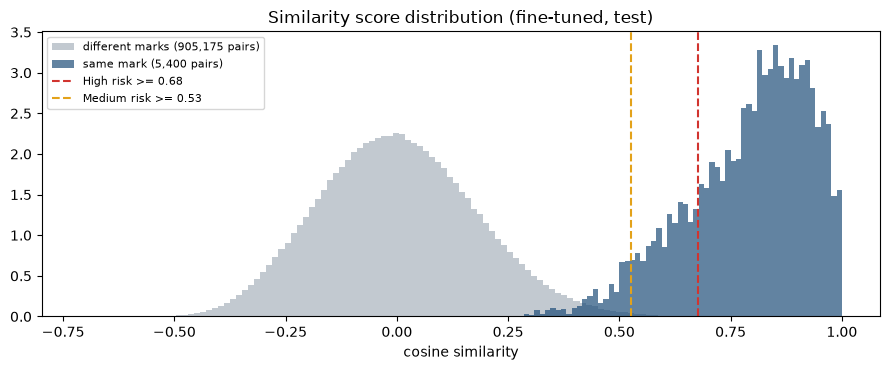

In [7]:
pos, neg = pair_scores(emb_ft, labels)
thresholds = choose_thresholds(pos, neg, high_precision=0.95, medium_precision=0.70)
with open(RESULTS / "thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)
print(json.dumps(thresholds, indent=2))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(neg, bins=120, density=True, alpha=0.6, color="#9aa5b1", label=f"different marks ({len(neg):,} pairs)")
ax.hist(pos, bins=60, density=True, alpha=0.7, color="#1f4e79", label=f"same mark ({len(pos):,} pairs)")
ax.axvline(thresholds["high"], color="#d1342f", ls="--", label=f"High risk >= {thresholds['high']:.2f}")
ax.axvline(thresholds["medium"], color="#e3a21a", ls="--", label=f"Medium risk >= {thresholds['medium']:.2f}")
ax.set_xlabel("cosine similarity")
ax.set_title("Similarity score distribution (fine-tuned, test)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "score_distribution.png", dpi=110, bbox_inches="tight")
plt.show()

* **High risk:** at or above this score, at least 95% of pairs in the test set are the same mark.
* **Medium risk:** at or above this score, at least 70% are the same mark.
* Below that the risk is **Low**, but a consultant can still review it.

The thresholds are saved to `results/thresholds.json` and used by the app.

## 5. Export the gallery for the Streamlit app
The app searches the **test** logos (marks the model never saw). Images are saved as compact JPEGs.

In [8]:
GALLERY = ROOT / "app" / "gallery"
GALLERY_IMG = GALLERY / "images"
if GALLERY_IMG.exists():
    shutil.rmtree(GALLERY_IMG)
GALLERY_IMG.mkdir(parents=True)

gallery_meta = test_df[["filename", "parent_id", "is_parent", "brand_text", "variant_types"]].copy()
gallery_meta["filename"] = gallery_meta.filename.str.replace(".png", ".jpg", regex=False)
for src, dst in zip(paths, gallery_meta.filename):
    Image.open(src).convert("RGB").save(GALLERY_IMG / dst, quality=88)

index = faiss.IndexFlatIP(emb_ft.shape[1])
index.add(emb_ft.astype(np.float32))
faiss.write_index(index, str(GALLERY / "index.faiss"))
gallery_meta.to_csv(GALLERY / "meta.csv", index=False)

size_mb = sum(p.stat().st_size for p in GALLERY.rglob("*") if p.is_file()) / 1e6
print(f"Gallery: {index.ntotal} logos, {size_mb:.1f} MB -> {GALLERY}")

Gallery: 1350 logos, 10.1 MB -> c:\Users\yunido\trademark-logo-similarity\app\gallery


## Conclusions ##

* Freezing CLIP and training only a small projection head (~2 MB) with batch-hard triplet
  loss improves **Recall@1 from 0.917 to 0.996** and **mAP from 0.690 to 0.967** on 150 marks
  never seen during training.
* The largest gains are on the modifications the baseline handled worst: **flip**
  (0.708 → 0.992), **suffix change** (0.829 → 1.000) and **grayscale** (0.837 → 0.980).
  Grayscale remains the hardest case.
* Calibrated thresholds: **High risk ≥ 0.68** (95% of pairs above it are the same mark,
  capturing 79% of true pairs) and **Medium risk ≥ 0.53** (70% precision, capturing 95%).
* Business value: a consultant reviews a ranked short list with a risk label instead of
  scanning thousands of logos.